# 02. Pelatihan & Evaluasi Komparatif 3 Strategi Fusi Hibrida NIDS
**Topik:** Deteksi Zero-Day Attack pada Network Traffic Menggunakan Hybrid Stacked Autoencoder dan Isolation Forest untuk Mengurangi False Positive  
**Dataset:** NF-UQ-NIDS-v2 (Streaming Parquet Partitions)  
**Tujuan Eksperimen:**  
Membandingkan tiga paradigma fusi keputusan anomali pada ruang representasi laten $Z \in \mathbb{R}^{16}$ dan galat rekonstruksi $MSE$:
1. **Strategi A (Weighted Linear Fusion, $\alpha = 0{,}5$):** Penggabungan skor linier terbobot untuk mengoptimalkan penekanan *False Positive Rate* (FPR).
2. **Strategi B (Max-Normalized Extreme Scoring):** Penyekalaan skor relatif terhadap ambang batas kalibrasi untuk menangkap anomali ekstrem.
3. **Strategi C (Decision Logic OR-Rule):** Penggabungan logika disjungsi biner ($pred_{SAE} \lor pred_{IF}$) untuk meminimalkan *False Negative Rate* (FNR) dan kebocoran serangan nir-hari.


In [1]:
# STREAMING_CHUNK:Configuring libraries and environment paths...
import os
import sys
import json
import shutil
from pathlib import Path
from typing import Dict, List, Tuple, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, IterableDataset

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    auc
)

# ============================================================
# KONFIGURASI PATH SISTEM TERSTANDARISASI
# ============================================================
BASE_DIR = Path.cwd().resolve()
DATA_DIR = Path(r"../dataset/processed")
ARTIFACTS_DIR = BASE_DIR / "artifacts"
RESULTS_DIR = BASE_DIR / "results"

ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = DATA_DIR / "benign_train_parts"
TEST_BENIGN_DIR = DATA_DIR / "benign_test_parts"
UNSEEN_ATTACK_DIR = DATA_DIR / "unseen_attack_test_parts"

META_PATH = DATA_DIR / "partition_metadata.json"
SCALER_PATH = ARTIFACTS_DIR / "minmax_params.json"
SAE_WEIGHTS_PATH = ARTIFACTS_DIR / "sae_autoencoder.pth"
SAE_CONFIG_PATH = ARTIFACTS_DIR / "sae_config.json"

# Parameter Reproducibility & Hyperparameter Model
SEED = 42
BATCH_SIZE = 256
EPOCHS = 5
LEARNING_RATE = 1e-3
ENCODER_DIMS = [64, 32]
LATENT_DIM = 16
DECODER_DIMS = [32, 64]
OUTPUT_ACTIVATION = "sigmoid"

MAX_TRAIN_SAMPLES_IFOREST = 50_000
IFOREST_CALIB_RATIO = 0.20
IFOREST_ESTIMATORS = 100
THRESHOLD_PERCENTILE = 95.0
ALPHA = 0.50

EVAL_BATCH_SIZE = 256
EVAL_MAX_BENIGN_SAMPLES = 25_000
EVAL_MAX_ATTACK_SAMPLES = 25_000

# Penguncian seed komputasi
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=== KONFIGURASI EKSEKUSI EXPERIMENT ===")
print("Direktori Kerja Aktif :", BASE_DIR)
print("Direktori Partisi Data:", DATA_DIR)
print("Device Komputasi      :", device)
if device.type == "cuda":
    print("GPU Terdeteksi        :", torch.cuda.get_device_name(0))

assert META_PATH.exists(), f"Metadata tidak ditemukan di {META_PATH}!"
assert SCALER_PATH.exists(), f"Scaler Min-Max tidak ditemukan di {SCALER_PATH}!"

with open(META_PATH, "r", encoding="utf-8") as f:
    meta_info = json.load(f)
feature_columns = meta_info["feature_columns"]
input_dim = len(feature_columns)

with open(SCALER_PATH, "r", encoding="utf-8") as f:
    scaler_info = json.load(f)
mins = np.array(scaler_info["min"], dtype=np.float32)
maxs = np.array(scaler_info["max"], dtype=np.float32)

train_files = sorted(TRAIN_DIR.glob("*.parquet"))
assert len(train_files) > 0, f"Partisi Parquet pelatihan kosong di {TRAIN_DIR}"

print(f"Fitur Masukan (d)     : {input_dim} fitur")
print(f"Total Partisi Train   : {len(train_files)} berkas Parquet")


=== KONFIGURASI EKSEKUSI EXPERIMENT ===
Direktori Kerja Aktif : I:\skripsi\NIDS\notebooks
Direktori Partisi Data: ..\dataset\processed
Device Komputasi      : cuda
GPU Terdeteksi        : NVIDIA GeForce RTX 3050 Laptop GPU
Fitur Masukan (d)     : 39 fitur
Total Partisi Train   : 1520 berkas Parquet


### Definisi Jaringan Syaraf Tiruan Stacked Autoencoder (SAE)
Arsitektur SAE dirancang simetris dengan kompresi bertingkat:
$$\mathbb{R}^{39} \xrightarrow{\text{Linear}} \mathbb{R}^{64} \xrightarrow{\text{ReLU}} \mathbb{R}^{32} \xrightarrow{\text{ReLU}} Z \in \mathbb{R}^{16} \xrightarrow{\text{ReLU}} \mathbb{R}^{32} \xrightarrow{\text{ReLU}} \mathbb{R}^{64} \xrightarrow{\text{Sigmoid}} \hat{X} \in \mathbb{R}^{39}$$
Model dilengkapi dua fungsi inferensi berbasis mini-batch GPU:
1. `get_latent_features`: Mengekstrak vektor $Z$ untuk masukan Isolation Forest.
2. `get_reconstruction_error`: Menghitung galat MSE horizontal per aliran paket.


In [2]:
# STREAMING_CHUNK:Defining Stacked Autoencoder architecture...
def minmax_transform_np(X: np.ndarray, mins: np.ndarray, maxs: np.ndarray) -> np.ndarray:
    denom = maxs - mins
    denom = np.where(np.isclose(denom, 0.0), 1.0, denom).astype(np.float32)
    return np.clip((X - mins) / denom, 0.0, 1.0).astype(np.float32)


class TrainParquetIterableDataset(IterableDataset):
    def __init__(self, files: List[Path], features: List[str], mins: np.ndarray, maxs: np.ndarray, batch_size: int = 256, seed: int = 42):
        self.files = list(files)
        self.features = features
        self.mins = mins
        self.maxs = maxs
        self.batch_size = batch_size
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch: int):
        self.epoch = epoch

    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch)
        file_list = list(self.files)
        rng.shuffle(file_list)

        for fpath in file_list:
            df = pd.read_parquet(fpath, columns=self.features)
            if df.empty:
                continue
            X = df.to_numpy(dtype=np.float32)
            finite_mask = np.isfinite(X).all(axis=1)
            X = X[finite_mask]
            if len(X) == 0:
                continue

            X_scaled = minmax_transform_np(X, self.mins, self.maxs)
            rng.shuffle(X_scaled)

            for start in range(0, len(X_scaled), self.batch_size):
                yield torch.from_numpy(X_scaled[start : start + self.batch_size])


class StackedAutoencoder(nn.Module):
    def __init__(self, input_dim: int, encoder_dims: List[int] = None, latent_dim: int = 16, decoder_dims: List[int] = None, output_activation: str = "sigmoid"):
        super().__init__()
        encoder_dims = encoder_dims or [64, 32]
        decoder_dims = decoder_dims or [32, 64]
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder (Kompresi Fitur ke Ruang Laten)
        encoder_layers = []
        prev = input_dim
        for d in encoder_dims:
            encoder_layers.append(nn.Linear(prev, d))
            encoder_layers.append(nn.ReLU())
            prev = d
        encoder_layers.append(nn.Linear(prev, latent_dim))
        encoder_layers.append(nn.ReLU())
        self.encoder = nn.Sequential(*encoder_layers)

        # Decoder (Rekonstruksi Fitur ke Dimensi Awal)
        decoder_layers = []
        prev = latent_dim
        for d in decoder_dims:
            decoder_layers.append(nn.Linear(prev, d))
            decoder_layers.append(nn.ReLU())
            prev = d
        decoder_layers.append(nn.Linear(prev, input_dim))

        if output_activation == "sigmoid":
            decoder_layers.append(nn.Sigmoid())
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.decoder(self.encoder(x))

    @torch.no_grad()
    def get_latent_features(self, x: np.ndarray, batch_size: int = 1024) -> np.ndarray:
        self.eval()
        arr = np.asarray(x, dtype=np.float32)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        if len(arr) == 0:
            return np.empty((0, self.latent_dim), dtype=np.float32)

        dev = next(self.parameters()).device
        latents = []
        for start in range(0, len(arr), batch_size):
            b_tensor = torch.from_numpy(arr[start : start + batch_size]).to(dev)
            latents.append(self.encoder(b_tensor).detach().cpu().numpy())
        return np.vstack(latents).astype(np.float32)

    @torch.no_grad()
    def get_reconstruction_error(self, x: np.ndarray, batch_size: int = 1024) -> np.ndarray:
        self.eval()
        arr = np.asarray(x, dtype=np.float32)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        if len(arr) == 0:
            return np.empty(0, dtype=np.float32)

        dev = next(self.parameters()).device
        errors = []
        for start in range(0, len(arr), batch_size):
            b_tensor = torch.from_numpy(arr[start : start + batch_size]).to(dev)
            recon = self(b_tensor)
            mse = torch.mean((b_tensor - recon) ** 2, dim=1)
            errors.append(mse.detach().cpu().numpy())
        return np.concatenate(errors).astype(np.float32)


sae_model = StackedAutoencoder(
    input_dim=input_dim,
    encoder_dims=ENCODER_DIMS,
    latent_dim=LATENT_DIM,
    decoder_dims=DECODER_DIMS,
    output_activation=OUTPUT_ACTIVATION,
).to(device)

if SAE_WEIGHTS_PATH.exists() and SAE_CONFIG_PATH.exists():
    print(f"[INFO] Artefak bobot SAE ditemukan di: {SAE_WEIGHTS_PATH}")
    print("Memuat bobot langsung dari checkpoint...")
    sae_model.load_state_dict(torch.load(SAE_WEIGHTS_PATH, map_location=device))
    sae_model.eval()
else:
    print("[INFO] Melakukan training streaming SAE (5 Epochs)...")
    train_dataset = TrainParquetIterableDataset(
        files=train_files,
        features=feature_columns,
        mins=mins,
        maxs=maxs,
        batch_size=BATCH_SIZE,
        seed=SEED,
    )
    train_loader = DataLoader(train_dataset, batch_size=None, num_workers=0)
    optimizer = torch.optim.Adam(sae_model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()

    for epoch in range(EPOCHS):
        sae_model.train()
        train_dataset.set_epoch(epoch)
        total_loss, samples = 0.0, 0

        for b_tensor in train_loader:
            b_gpu = b_tensor.to(device)
            optimizer.zero_grad()
            recon = sae_model(b_gpu)
            loss = criterion(recon, b_gpu)
            loss.backward()
            optimizer.step()

            bs = b_tensor.size(0)
            total_loss += loss.item() * bs
            samples += bs

        ep_loss = total_loss / max(samples, 1)
        print(f"Epoch {epoch + 1}/{EPOCHS} Selesai | Sampel: {samples:,} | Train MSE: {ep_loss:.6f}")

    torch.save(sae_model.state_dict(), SAE_WEIGHTS_PATH)
    with open(SAE_CONFIG_PATH, "w", encoding="utf-8") as f:
        json.dump({
            "input_dim": input_dim,
            "encoder_dims": ENCODER_DIMS,
            "latent_dim": LATENT_DIM,
            "decoder_dims": DECODER_DIMS,
            "output_activation": OUTPUT_ACTIVATION,
        }, f, indent=4)
    print("Model SAE berhasil disimpan.")


[INFO] Melakukan training streaming SAE (5 Epochs)...
Epoch 1/5 Selesai | Sampel: 20,133,027 | Train MSE: 0.000274
Epoch 2/5 Selesai | Sampel: 20,133,027 | Train MSE: 0.000026
Epoch 3/5 Selesai | Sampel: 20,133,027 | Train MSE: 0.000009
Epoch 4/5 Selesai | Sampel: 20,133,027 | Train MSE: 0.000008
Epoch 5/5 Selesai | Sampel: 20,133,027 | Train MSE: 0.000008
Model SAE berhasil disimpan.


### Pelatihan Isolation Forest pada Ruang Laten $Z \in \mathbb{R}^{16}$
Sebanyak 50.000 sampel aliran normal diambil secara terdistribusi dari partisi latih:
- **80% (40.000 sampel):** Digunakan untuk fitting struktur pohon isolasi (*iTrees*).
- **20% (10.000 sampel):** Disimpan sebagai himpunan data kalibrasi ambang batas (*threshold calibration set*) tanpa kebocoran data.


In [3]:
# STREAMING_CHUNK:Fitting Isolation Forest and calibrating thresholds...
print(f"Mengekstraksi {MAX_TRAIN_SAMPLES_IFOREST:,} sampel laten dari partisi Benign Train...")
rng = np.random.default_rng(SEED)
shuffled_files = list(train_files)
rng.shuffle(shuffled_files)

Z_list, S_list = [], []
total_collected = 0

for fpath in shuffled_files:
    if total_collected >= MAX_TRAIN_SAMPLES_IFOREST:
        break
    df = pd.read_parquet(fpath, columns=feature_columns)
    if df.empty:
        continue
    X = df.to_numpy(dtype=np.float32)
    finite_mask = np.isfinite(X).all(axis=1)
    X = X[finite_mask]
    if len(X) == 0:
        continue

    X_scaled = minmax_transform_np(X, mins, maxs)
    perm = rng.permutation(len(X_scaled))
    X_scaled = X_scaled[perm]

    rem = MAX_TRAIN_SAMPLES_IFOREST - total_collected
    X_batch = X_scaled[:rem]

    z = sae_model.get_latent_features(X_batch)
    s = sae_model.get_reconstruction_error(X_batch)

    Z_list.append(z)
    S_list.append(s)
    total_collected += len(X_batch)

Z_all = np.vstack(Z_list)
sae_train_raw = np.concatenate(S_list)

# Gabungkan representasi laten Z (16 dim) dan MSE (1 dim) menjadi 17 dimensi
cascaded_train_all = np.hstack([Z_all, sae_train_raw.reshape(-1, 1)])

calib_len = int(len(cascaded_train_all) * IFOREST_CALIB_RATIO)
cascaded_fit = cascaded_train_all[calib_len:]
cascaded_calib = cascaded_train_all[:calib_len]
sae_calib_raw = sae_train_raw[:calib_len]

print(f"Sampel Fit IForest       : {len(cascaded_fit):,} aliran")
print(f"Sampel Kalibrasi Ambang : {len(cascaded_calib):,} aliran")

iforest = IsolationForest(
    n_estimators=IFOREST_ESTIMATORS,
    contamination="auto",
    random_state=SEED,
    n_jobs=-1,
)
iforest.fit(cascaded_fit)
print("Isolation Forest berhasil dilatih pada ruang laten Z (16 dimensi).")

def normalize_with_bounds(scores: np.ndarray, bounds: Tuple[float, float]) -> np.ndarray:
    s = np.asarray(scores, dtype=np.float64)
    min_val, max_val = bounds
    denom = max_val - min_val
    if np.isclose(denom, 0.0):
        return np.zeros_like(s, dtype=np.float32)
    return np.clip((s - min_val) / denom, 0.0, 1.0).astype(np.float32)

# Gunakan matriks kaskade 17 dimensi
if_train_raw = -iforest.score_samples(cascaded_train_all)
sae_bounds = (float(np.min(sae_train_raw)), float(np.max(sae_train_raw)))
if_bounds = (float(np.min(if_train_raw)), float(np.max(if_train_raw)))

sae_calib_norm = normalize_with_bounds(sae_calib_raw, sae_bounds)
if_calib_raw = -iforest.score_samples(cascaded_calib)
if_calib_norm = normalize_with_bounds(if_calib_raw, if_bounds)

# 1. Ambang Batas Baseline Individual
tau_sae = float(np.percentile(sae_calib_norm, THRESHOLD_PERCENTILE))
tau_if = float(np.percentile(if_calib_norm, THRESHOLD_PERCENTILE))

# 2. Ambang Batas Strategi A (Weighted Linear)
hybrid_linear_calib = ALPHA * sae_calib_norm + (1.0 - ALPHA) * if_calib_norm
tau_linear = float(np.percentile(hybrid_linear_calib, THRESHOLD_PERCENTILE))

# 3. Ambang Batas Strategi B (Max-Normalized)
safe_tau_sae = max(tau_sae, 1e-6)
safe_tau_if = max(tau_if, 1e-6)
hybrid_maxnorm_calib = np.maximum(sae_calib_norm / safe_tau_sae, if_calib_norm / safe_tau_if)
tau_maxnorm = float(np.percentile(hybrid_maxnorm_calib, THRESHOLD_PERCENTILE))

print("\n=== KALIBRASI AMBANG BATAS (PERSENTIL 95% DATA NORMAL) ===")
print(f"Tau SAE               : {tau_sae:.6f}")
print(f"Tau IForest           : {tau_if:.6f}")
print(f"Tau Strategi A (Linear): {tau_linear:.6f}")
print(f"Tau Strategi B (Max-N) : {tau_maxnorm:.6f}")
print(f"Tau Strategi C (OR)    : [Tau SAE: {tau_sae:.6f} | Tau IF: {tau_if:.6f}]")


Mengekstraksi 50,000 sampel laten dari partisi Benign Train...
Sampel Fit IForest       : 40,000 aliran
Sampel Kalibrasi Ambang : 10,000 aliran
Isolation Forest berhasil dilatih pada ruang laten Z (16 dimensi).

=== KALIBRASI AMBANG BATAS (PERSENTIL 95% DATA NORMAL) ===
Tau SAE               : 0.000576
Tau IForest           : 0.475402
Tau Strategi A (Linear): 0.237980
Tau Strategi B (Max-N) : 1.162009
Tau Strategi C (OR)    : [Tau SAE: 0.000576 | Tau IF: 0.475402]


### Pengumpulan Data Uji Evaluasi
Data uji diambil seimbang ($N = 50.000$):
- **25.000 aliran:** Normal (*Benign Test Parts*).
- **25.000 aliran:** Serangan tak dikenal (*Unseen Attack Parts - DDoS*).


In [4]:
# STREAMING_CHUNK:Evaluating comparative multi-strategy metrics...
test_benign_files = sorted(TEST_BENIGN_DIR.glob("*.parquet"))
unseen_attack_files = sorted(UNSEEN_ATTACK_DIR.glob("*.parquet"))

def collect_scores(files: List[Path], max_samples: int, seed: int) -> Dict[str, np.ndarray]:
    rng_test = np.random.default_rng(seed)
    shuffled = list(files)
    rng_test.shuffle(shuffled)

    sae_norm_l, if_norm_l, y_l = [], [], []
    total = 0

    for fpath in shuffled:
        if total >= max_samples:
            break
        df = pd.read_parquet(fpath, columns=feature_columns + ["Label"])
        if df.empty:
            continue
        X = df[feature_columns].to_numpy(dtype=np.float32)
        finite_mask = np.isfinite(X).all(axis=1)
        if not finite_mask.all():
            X = X[finite_mask]
            df = df.loc[finite_mask]
        if len(X) == 0:
            continue

        X_scaled = minmax_transform_np(X, mins, maxs)
        y = df["Label"].astype(int).to_numpy()

        rem = max_samples - total
        X_scaled = X_scaled[:rem]
        y = y[:rem]

        for start in range(0, len(X_scaled), EVAL_BATCH_SIZE):
            bx = X_scaled[start : start + EVAL_BATCH_SIZE]
            by = y[start : start + EVAL_BATCH_SIZE]

            z_batch = sae_model.get_latent_features(bx)
            s_raw = sae_model.get_reconstruction_error(bx)
            
            # Bentuk vektor kaskade [Z, MSE] untuk evaluasi IForest
            cascaded_batch = np.hstack([z_batch, s_raw.reshape(-1, 1)])
            i_raw = -iforest.score_samples(cascaded_batch)

            sae_norm_l.append(normalize_with_bounds(s_raw, sae_bounds))
            if_norm_l.append(normalize_with_bounds(i_raw, if_bounds))
            y_l.append(by)

        total += len(X_scaled)

    return {
        "sae_norm": np.concatenate(sae_norm_l),
        "if_norm": np.concatenate(if_norm_l),
        "y": np.concatenate(y_l),
    }

print("Mengumpulkan data evaluasi Benign Test...")
benign_data = collect_scores(test_benign_files, EVAL_MAX_BENIGN_SAMPLES, SEED)
print("Mengumpulkan data evaluasi Unseen Attack Test...")
attack_data = collect_scores(unseen_attack_files, EVAL_MAX_ATTACK_SAMPLES, SEED + 1)

y_true = np.concatenate([benign_data["y"], attack_data["y"]])
sae_test_norm = np.concatenate([benign_data["sae_norm"], attack_data["sae_norm"]])
if_test_norm = np.concatenate([benign_data["if_norm"], attack_data["if_norm"]])

print(f"\nTotal Data Uji Evaluasi : {len(y_true):,} aliran")
print(f"- Benign (Normal)       : {int((y_true == 0).sum()):,} aliran")
print(f"- Unseen Attack (DDoS)  : {int((y_true == 1).sum()):,} aliran")

# 1. Prediksi Baseline
pred_sae = (sae_test_norm > tau_sae).astype(int)
pred_if = (if_test_norm > tau_if).astype(int)

# 2. Prediksi Strategi A: Weighted Linear Fusion (alpha = 0.5)
score_linear = ALPHA * sae_test_norm + (1.0 - ALPHA) * if_test_norm
pred_linear = (score_linear > tau_linear).astype(int)

# 3. Prediksi Strategi B: Max-Normalized Scoring
score_maxnorm = np.maximum(sae_test_norm / safe_tau_sae, if_test_norm / safe_tau_if)
pred_maxnorm = (score_maxnorm > tau_maxnorm).astype(int)

# 4. Prediksi Strategi C: Decision Logic OR-Rule
pred_or_rule = (pred_sae | pred_if).astype(int)

def compute_metrics(y_t: np.ndarray, y_p: np.ndarray, scores: np.ndarray = None, threshold_val: Any = None) -> Dict[str, Any]:
    cm = confusion_matrix(y_t, y_p, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    fpr = float(fp / (fp + tn)) if (fp + tn) > 0 else 0.0
    fnr = float(fn / (fn + tp)) if (fn + tp) > 0 else 0.0
    prec = float(precision_score(y_t, y_p, pos_label=1, zero_division=0))
    rec = float(recall_score(y_t, y_p, pos_label=1, zero_division=0))
    f1 = float(f1_score(y_t, y_p, pos_label=1, zero_division=0))
    roc_auc = float(roc_auc_score(y_t, scores)) if scores is not None else None
    pr_auc = float(average_precision_score(y_t, scores)) if scores is not None else None

    return {
        "Threshold": threshold_val,
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
        "FPR (%)": round(fpr * 100, 2),
        "FNR (%)": round(fnr * 100, 2),
        "Precision (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4) if roc_auc is not None else "-",
        "PR-AUC": round(pr_auc, 4) if pr_auc is not None else "-",
    }

metrics_summary = {
    "Baseline 1: SAE Alone": compute_metrics(y_true, pred_sae, sae_test_norm, round(tau_sae, 6)),
    "Baseline 2: IForest Alone": compute_metrics(y_true, pred_if, if_test_norm, round(tau_if, 6)),
    "Strategi A: Weighted Linear (α=0.5)": compute_metrics(y_true, pred_linear, score_linear, round(tau_linear, 6)),
    "Strategi B: Max-Normalized Fusion": compute_metrics(y_true, pred_maxnorm, score_maxnorm, round(tau_maxnorm, 6)),
    "Strategi C: Decision Logic OR-Rule": compute_metrics(y_true, pred_or_rule, score_maxnorm, "OR Rule"),
}

df_comparison = pd.DataFrame(metrics_summary).T

print("\n" + "=" * 95)
print("HASIL EVALUASI KOMPARATIF 3 STRATEGI FUSI HYBRID NIDS (NF-UQ-NIDS-v2)")
print("=" * 95)
print(df_comparison[["FPR (%)", "FNR (%)", "Precision (%)", "Recall (%)", "F1-Score", "ROC-AUC"]].to_string())
print("=" * 95)

# Simpan ke JSON
metrics_json_path = RESULTS_DIR / "multi_strategy_metrics.json"
with open(metrics_json_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=4)
print(f"Hasil lengkap tersimpan di: {metrics_json_path}")


Mengumpulkan data evaluasi Benign Test...
Mengumpulkan data evaluasi Unseen Attack Test...

Total Data Uji Evaluasi : 50,000 aliran
- Benign (Normal)       : 25,000 aliran
- Unseen Attack (DDoS)  : 25,000 aliran

HASIL EVALUASI KOMPARATIF 3 STRATEGI FUSI HYBRID NIDS (NF-UQ-NIDS-v2)
                                    FPR (%) FNR (%) Precision (%) Recall (%) F1-Score ROC-AUC
Baseline 1: SAE Alone                   4.4    9.83         95.35      90.17   0.9269  0.9626
Baseline 2: IForest Alone              5.21   10.72         94.49      89.28   0.9181  0.9752
Strategi A: Weighted Linear (α=0.5)     5.2   10.72         94.49      89.28   0.9181  0.9751
Strategi B: Max-Normalized Fusion      4.62    9.51         95.15      90.49   0.9276  0.9678
Strategi C: Decision Logic OR-Rule     7.74    9.47         92.12      90.53   0.9132  0.9678
Hasil lengkap tersimpan di: I:\skripsi\NIDS\notebooks\results\multi_strategy_metrics.json


### Visualisasi Komparatif Hasil Evaluasi
Dua grafik dibuat untuk menganalisis performa deteksi:
1. **Kurva ROC:** Mengukur separasi bimodal skor anomali kontinu (SAE, IForest, Strategi A, dan Strategi B).
2. **Bar Chart Trade-off (FPR vs FNR):** Mengilustrasikan pergeseran tingkat alarm palsu vs tingkat serangan lolos pada kelima model.


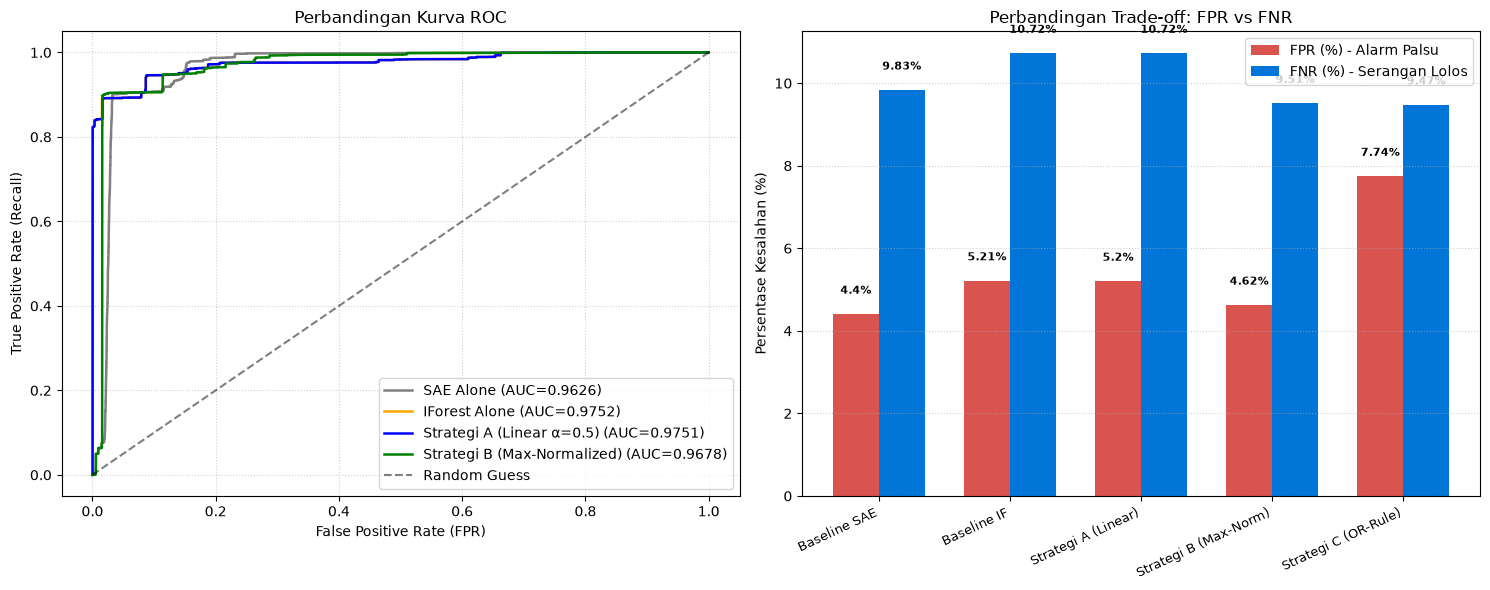

Visualisasi grafik komparatif berhasil disimpan di: I:\skripsi\NIDS\notebooks\results\multi_strategy_comparison.png
[SELESAI] Eksperimen multi-strategi fusi berhasil dieksekusi secara terpadu.


In [5]:
# STREAMING_CHUNK:Plotting and saving comparative evaluation curves...
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot Kurva ROC
plot_dict = {
    "SAE Alone": (sae_test_norm, "gray"),
    "IForest Alone": (if_test_norm, "orange"),
    "Strategi A (Linear α=0.5)": (score_linear, "blue"),
    "Strategi B (Max-Normalized)": (score_maxnorm, "green"),
}

for name, (scores, color) in plot_dict.items():
    fpr_v, tpr_v, _ = roc_curve(y_true, scores)
    auc_v = auc(fpr_v, tpr_v)
    axes[0].plot(fpr_v, tpr_v, label=f"{name} (AUC={auc_v:.4f})", linewidth=1.8, color=color)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess")
axes[0].set_title("Perbandingan Kurva ROC", fontsize=12)
axes[0].set_xlabel("False Positive Rate (FPR)", fontsize=10)
axes[0].set_ylabel("True Positive Rate (Recall)", fontsize=10)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="lower right")

# Plot Bar Chart Trade-off FPR vs FNR
strategies = ["Baseline SAE", "Baseline IF", "Strategi A (Linear)", "Strategi B (Max-Norm)", "Strategi C (OR-Rule)"]
fpr_vals = [metrics_summary[k]["FPR (%)"] for k in metrics_summary]
fnr_vals = [metrics_summary[k]["FNR (%)"] for k in metrics_summary]

x_idx = np.arange(len(strategies))
width = 0.35

axes[1].bar(x_idx - width/2, fpr_vals, width, label="FPR (%) - Alarm Palsu", color="#d9534f")
axes[1].bar(x_idx + width/2, fnr_vals, width, label="FNR (%) - Serangan Lolos", color="#0275d8")

axes[1].set_title("Perbandingan Trade-off: FPR vs FNR", fontsize=12)
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(strategies, rotation=25, ha="right", fontsize=9)
axes[1].set_ylabel("Persentase Kesalahan (%)", fontsize=10)
axes[1].grid(True, linestyle=":", alpha=0.6, axis="y")
axes[1].legend()

for i in range(len(strategies)):
    axes[1].text(x_idx[i] - width/2, fpr_vals[i] + 0.5, f"{fpr_vals[i]}%", ha="center", fontsize=8, fontweight="bold")
    axes[1].text(x_idx[i] + width/2, fnr_vals[i] + 0.5, f"{fnr_vals[i]}%", ha="center", fontsize=8, fontweight="bold")

plt.tight_layout()
curve_output = RESULTS_DIR / "multi_strategy_comparison.png"
plt.savefig(curve_output, dpi=300, bbox_inches="tight")
plt.show()

print(f"Visualisasi grafik komparatif berhasil disimpan di: {curve_output}")
print("[SELESAI] Eksperimen multi-strategi fusi berhasil dieksekusi secara terpadu.")
